## Impurity-based feature ranking (4.1.2)

Impurity-based ranking of the top N SBP and DBP features (using the feature_importances_ function) for both the subject independent and dependent modes.

In [39]:
'''
The following code ranks the features using the built in .feature_importances_ function for forestRegressors, in a subject dependent
fashion, i.e. with subject leakage
'''
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pickle
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, GroupKFold
from collections import defaultdict
import os

In [40]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")

def load_all_data():
    """
    Load and combine all pre-split folds into one dataset
    
    The original dataset comes pre-split into 5 folds, but I combine them so I can split using
    groups over the patient id
    """
    all_folds = []
    for fold_num in range(5):
        fold_data = load_data(fold_num)
        all_folds.append(fold_data)
    
    combined = pd.concat(all_folds, ignore_index=True)
    print(f"Combined dataset shape: {combined.shape}")
    print(f"Total samples: {len(combined)}")
    
    return combined

def prepare_data(data):
    '''
    Extract the targets, features and patient ID's (groups) from the dataset

    Structure of data: 
    - Column 0: patient (used to in GroupKFold to prevent patient leakage)
    - Column 1: trial
    - Column 2: SBP
    - Column 3: DBP
    - Columns 4+: features
    '''
    y_SBP = data.iloc[:,2].values
    y_DBP = data.iloc[:,3].values
    X = data.iloc[:,4:]
    groups = data.iloc[:, 0].values

    print(f"\nDataset summary:")
    print(f"    Features: {X.shape[1]}")
    print(f"    Samples: {len(X)}")
    print(f"    Unique patients: {len(np.unique(groups))}")
    print(f"    SBP range: [{y_SBP.min():.4f}, {y_SBP.max():.4f}]")
    print(f"    DBP range: [{y_DBP.min():.4f}, {y_DBP.max():.4f}]")

    return y_SBP, y_DBP, X, groups


In [41]:
def plot_results(results, TOP_N_FEATURES, output_folder='results'):

    os.makedirs(output_folder, exist_ok=True)
    
    for mode in results.keys():
        fig, axes = plt.subplots(1, 2, figsize=(16, 8))
        
        # SBP plot
        sbp_top = results[mode]["SBP"].sort_values(ascending=True).tail(TOP_N_FEATURES)
        sbp_top.plot.barh(ax=axes[0], color="skyblue", edgecolor='navy', linewidth=0.5)
        axes[0].set_title(
            f'Top {TOP_N_FEATURES} Features for SBP\n'
            f'{mode.replace("_", " ").title()} CV',
            fontsize=14, fontweight='bold'
        )
        axes[0].set_xlabel('Increase in MAE', fontsize=12)
        axes[0].set_ylabel('Feature', fontsize=12)
        axes[0].axvline(x=0, color='red', linestyle='--', linewidth=1, alpha=0.7)
        axes[0].grid(axis='x', alpha=0.3)
        
        # DBP plot
        dbp_top = results[mode]["DBP"].sort_values(ascending=True).tail(TOP_N_FEATURES)
        dbp_top.plot.barh(ax=axes[1], color="lightgreen", edgecolor='darkgreen', linewidth=0.5)
        axes[1].set_title(
            f'Top {TOP_N_FEATURES} Features for DBP\n'
            f'{mode.replace("_", " ").title()} CV',
            fontsize=14, fontweight='bold'
        )
        axes[1].set_xlabel('Increase in MAE', fontsize=12)
        axes[1].set_ylabel('Feature', fontsize=12)
        axes[1].axvline(x=0, color='red', linestyle='--', linewidth=1, alpha=0.7)
        axes[1].grid(axis='x', alpha=0.3)
        
        plt.tight_layout()
        
        filename = os.path.join(output_folder, f'FeatureRanking_Impurity_{mode}.png')
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        plt.show()


Running mode: subject_independent (benchmark folds)
    Fold 1/5 | SBP MAE: 18.7976
    | DBP MAE: 10.2165
    Fold 2/5 | SBP MAE: 13.3006
    | DBP MAE: 7.3745
    Fold 3/5 | SBP MAE: 9.7708
    | DBP MAE: 5.9969
    Fold 4/5 | SBP MAE: 10.7520
    | DBP MAE: 9.8099
    Fold 5/5 | SBP MAE: 9.6550
    | DBP MAE: 6.2744
    Fold 1/5 | SBP MAE: 18.8473
    | DBP MAE: 10.3286
    Fold 2/5 | SBP MAE: 13.1611
    | DBP MAE: 7.1547
    Fold 3/5 | SBP MAE: 9.8109
    | DBP MAE: 5.8854
    Fold 4/5 | SBP MAE: 10.8398
    | DBP MAE: 9.9023
    Fold 5/5 | SBP MAE: 9.6137
    | DBP MAE: 6.2053
    Fold 1/5 | SBP MAE: 19.4218
    | DBP MAE: 10.2587
    Fold 2/5 | SBP MAE: 13.2850
    | DBP MAE: 7.0461
    Fold 3/5 | SBP MAE: 9.4917
    | DBP MAE: 5.9576
    Fold 4/5 | SBP MAE: 10.6009
    | DBP MAE: 9.8927
    Fold 5/5 | SBP MAE: 9.5855
    | DBP MAE: 6.1832

Running mode: subject_dependent (KFold)
Combined dataset shape: (3063, 222)
Total samples: 3063

Dataset summary:
    Features: 218
    Sam

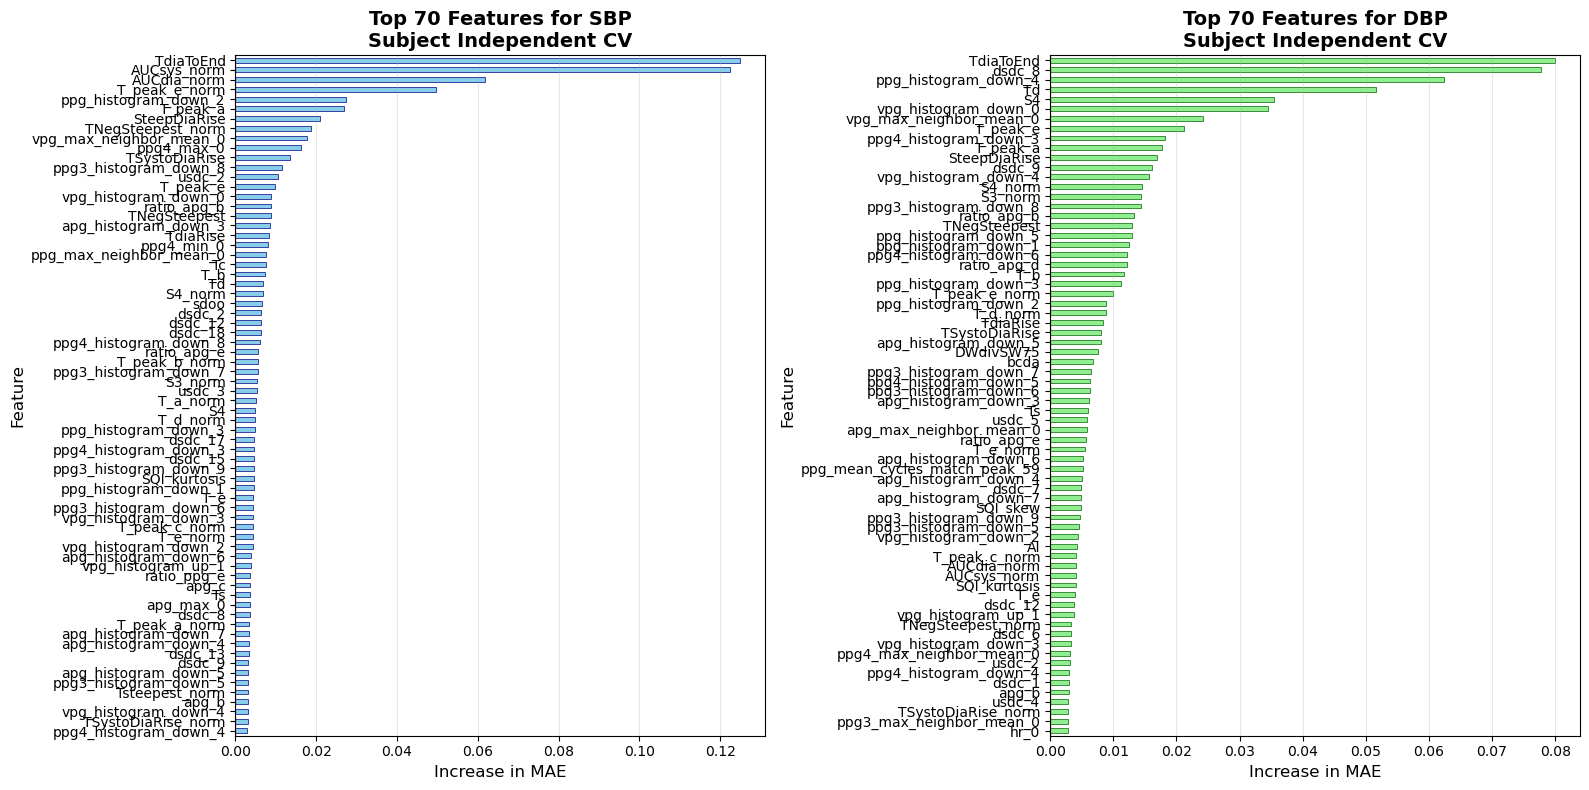

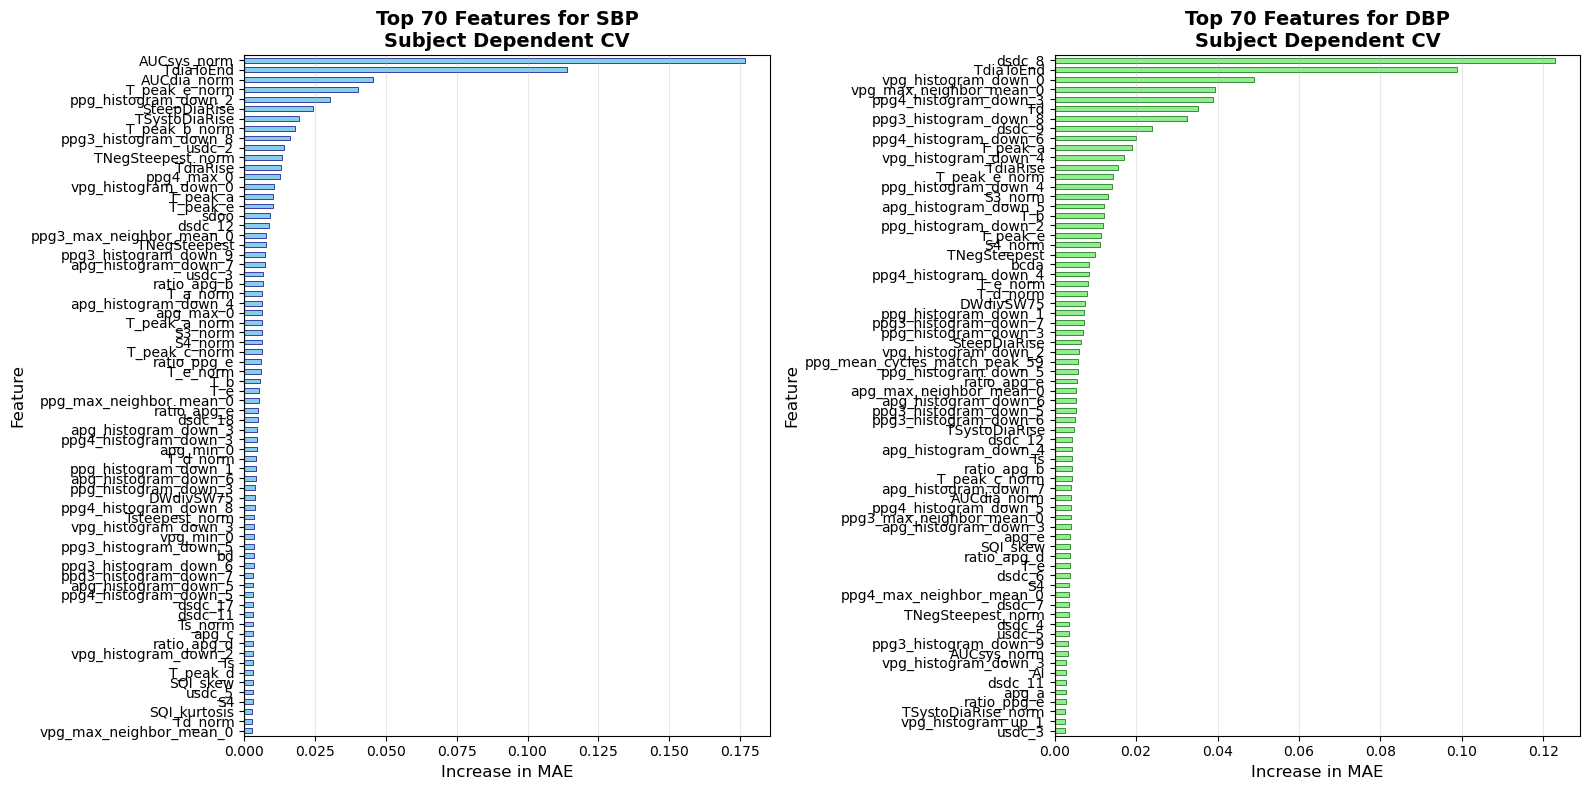


MODE: SUBJECT INDEPENDENT

Top 70 SBP Features:
   1. TdiaToEnd                                0.124891
   2. AUCsys_norm                              0.122520
   3. AUCdia_norm                              0.061801
   4. T_peak_e_norm                            0.049611
   5. ppg_histogram_down_2                     0.027277
   6. T_peak_a                                 0.026807
   7. SteepDiaRise                             0.021061
   8. TNegSteepest_norm                        0.018698
   9. vpg_max_neighbor_mean_0                  0.017630
  10. ppg4_max_0                               0.016255
  11. TSystoDiaRise                            0.013631
  12. ppg3_histogram_down_8                    0.011476
  13. usdc_2                                   0.010666
  14. T_peak_e                                 0.009777
  15. vpg_histogram_down_0                     0.008900
  16. ratio_apg_b                              0.008752
  17. TNegSteepest                             0.008698

In [42]:
n_splits = 5
seeds = [42,12,77]
N_ESTIMATORS = 100
TOP_N_FEATURES = 70

results = {}

# ── Subject-independent: benchmark's pre-split folds ──────────
print(f'\n{"="*70}')
print(f'Running mode: subject_independent (benchmark folds)')
print(f'{"="*70}')

feat_imp_SBP = defaultdict(list)
feat_imp_DBP = defaultdict(list)

for seed in seeds:
    for fold in range(n_splits):
        train_data = pd.concat([load_data(i) for i in range(n_splits) if i != fold])
        feature_cols = train_data.columns[4:]
        X_train = train_data[feature_cols]
        y_SBP_train = train_data.iloc[:, 2].values
        y_DBP_train = train_data.iloc[:, 3].values

        X_val = load_data(fold)[feature_cols]
        y_SBP_val = load_data(fold).iloc[:, 2].values
        y_DBP_val = load_data(fold).iloc[:, 3].values

        rf_SBP = RandomForestRegressor(n_estimators=N_ESTIMATORS, random_state=seed, n_jobs=-1)
        rf_SBP.fit(X_train, y_SBP_train)
        mae_SBP = mean_absolute_error(y_SBP_val, rf_SBP.predict(X_val))
        print(f'    Fold {fold+1}/{n_splits} | SBP MAE: {mae_SBP:.4f}')
        for i, feature in enumerate(feature_cols):
            feat_imp_SBP[feature].append(rf_SBP.feature_importances_[i])

        rf_DBP = RandomForestRegressor(n_estimators=N_ESTIMATORS, random_state=seed, n_jobs=-1)
        rf_DBP.fit(X_train, y_DBP_train)
        mae_DBP = mean_absolute_error(y_DBP_val, rf_DBP.predict(X_val))
        print(f'    | DBP MAE: {mae_DBP:.4f}')
        for i, feature in enumerate(feature_cols):
            feat_imp_DBP[feature].append(rf_DBP.feature_importances_[i])

results["subject_independent"] = {
    "SBP": pd.Series({f: np.mean(scores) for f, scores in feat_imp_SBP.items()}).sort_values(ascending=False),
    "DBP": pd.Series({f: np.mean(scores) for f, scores in feat_imp_DBP.items()}).sort_values(ascending=False),
}

# ── Subject-dependent: KFold (same as drop-column) ────────────
print(f'\n{"="*70}')
print(f'Running mode: subject_dependent (KFold)')
print(f'{"="*70}')

combined_data = load_all_data()
y_SBP, y_DBP, X, groups = prepare_data(combined_data)
feature_cols = X.columns.tolist()

feat_imp_SBP = defaultdict(list)
feat_imp_DBP = defaultdict(list)

for seed in seeds:
    splitter = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    splits = list(splitter.split(X, y_SBP))

    for fold, (train_idx, val_idx) in enumerate(splits, 1):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_SBP_train, y_SBP_val = y_SBP[train_idx], y_SBP[val_idx]
        y_DBP_train, y_DBP_val = y_DBP[train_idx], y_DBP[val_idx]

        rf_SBP = RandomForestRegressor(n_estimators=N_ESTIMATORS, random_state=seed, n_jobs=-1)
        rf_SBP.fit(X_train, y_SBP_train)
        mae_SBP = mean_absolute_error(y_SBP_val, rf_SBP.predict(X_val))
        print(f'    Fold {fold}/{n_splits} | SBP MAE: {mae_SBP:.4f}')
        for i, feature in enumerate(feature_cols):
            feat_imp_SBP[feature].append(rf_SBP.feature_importances_[i])

        rf_DBP = RandomForestRegressor(n_estimators=N_ESTIMATORS, random_state=seed, n_jobs=-1)
        rf_DBP.fit(X_train, y_DBP_train)
        mae_DBP = mean_absolute_error(y_DBP_val, rf_DBP.predict(X_val))
        print(f'    | DBP MAE: {mae_DBP:.4f}')
        for i, feature in enumerate(feature_cols):
            feat_imp_DBP[feature].append(rf_DBP.feature_importances_[i])

results["subject_dependent"] = {
    "SBP": pd.Series({f: np.mean(scores) for f, scores in feat_imp_SBP.items()}).sort_values(ascending=False),
    "DBP": pd.Series({f: np.mean(scores) for f, scores in feat_imp_DBP.items()}).sort_values(ascending=False),
}

plot_results(results, TOP_N_FEATURES=TOP_N_FEATURES, output_folder="FeatureRanking_Results")

for mode in results.keys():
    print(f'\n{"="*70}')
    print(f'MODE: {mode.upper().replace("_", " ")}')
    print(f'{"="*70}')
    for target in ["SBP", "DBP"]:
        importance = results[mode][target]
        print(f'\nTop {TOP_N_FEATURES} {target} Features:')
        for i, (feat, imp) in enumerate(importance.head(TOP_N_FEATURES).items(), 1):
            print(f'  {i:2d}. {feat:40s} {imp:.6f}')

## Save Results

In [43]:
output_path = Path("FeatureRanking_Results")
output_path.mkdir(exist_ok=True)
file_path = output_path / "rf_results.pkl"

if file_path.exists():
    with open(file_path, "rb") as f:
        res = pickle.load(f)
    print("Loaded existing results, updating impurity rankings")
else:
    res = {}
    print("Creating new file")

res.update({
    "folds": n_splits,
    "seeds": seeds,
    "n_estimator": N_ESTIMATORS,
    "sbp_ranking": list(zip(
        results["subject_independent"]["SBP"].index,
        results["subject_independent"]["SBP"].values
    )),
    "dbp_ranking": list(zip(
        results["subject_independent"]["DBP"].index,
        results["subject_independent"]["DBP"].values
    )),
    "sbp_ranking_subject_dependent": list(zip(
        results["subject_dependent"]["SBP"].index,
        results["subject_dependent"]["SBP"].values
    )),
    "dbp_ranking_subject_dependent": list(zip(
        results["subject_dependent"]["DBP"].index,
        results["subject_dependent"]["DBP"].values
    )),
})

with open(file_path, "wb") as f:
    pickle.dump(res, f)

print(f"Results saved to {file_path}")
print(f"Keys: {list(res.keys())}")

Loaded existing results, updating impurity rankings
Results saved to FeatureRanking_Results/rf_results.pkl
Keys: ['folds', 'seeds', 'n_estimator', 'sbp_ranking', 'dbp_ranking', 'sbp_ranking_subject_dependent', 'dbp_ranking_subject_dependent', 'sbp_ranking_pearson_impurity_indep', 'dbp_ranking_pearson_impurity_indep', 'sbp_ranking_spearman_impurity_indep', 'dbp_ranking_spearman_impurity_indep']
